# An explicit coined hypercube search

This notebook checks one **SKW-style quantum-walk search primitive** on a four-dimensional hypercube with 16 vertices. The supplied marked vertex is `5` (`0101`) and the number of walk steps is fixed at **four** before checking the probability scan. The target is a teaching equality predicate used to construct the circuit. These results do not establish a database-search benchmark, a MaxCut optimizer, or an application speedup.

The circuit contains the state preparation, joint coin/position marking operation, coin reflection, explicit controlled shifts, clean-work uncomputation, and final measurements of **all 11 qubits**. An independent classical matrix checks the ideal amplitudes. Counts are seeded classical draws from circuit statevector probabilities; a physical device is not executed. Workspace outcomes remain in the distribution and are never filtered.

The method follows Shenvi, Kempe and Whaley {cite:p}`opt_skw2003`, *Quantum random-walk search algorithm*, Physical Review A 67, 052307 (2003), DOI `10.1103/PhysRevA.67.052307`. Our original circuit construction uses a binary coin and a clean CCX chain. It differs from the standard uncontrolled SKW step by an overall minus sign. This notebook is a bounded numerical implementation check, not a formal proof of the full algorithm.

Use the pinned Python 3.12 environment. The notebook loads the actual worktree source explicitly, or the matching walk `optimization.py` download placed beside it. The implementation and notebook are MIT; the output below records exact Qiskit, NumPy and Matplotlib versions.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import math
import platform
import sys

# Load this checkout explicitly; do not use another editable installation.
cwd = Path.cwd().resolve()
candidates = [
    ("checkout", cwd / "src/openquantum/optimization.py"),
    ("checkout", cwd.parent / "src/openquantum/optimization.py"),
    ("standalone walk download", cwd / "optimization.py"),
    ("standalone walk download", cwd / "notebooks/optimization.py"),
]
selected = next(((kind, path.resolve()) for kind, path in candidates if path.is_file()), None)
if selected is None:
    raise FileNotFoundError("Save walk/optimization.py beside this notebook, or run from its checkout.")
source_kind, module_path = selected
spec = importlib.util.spec_from_file_location("optimization_walk_notebook_source", module_path)
opt = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = opt
spec.loader.exec_module(opt)
assert Path(opt.__file__).resolve() == module_path
if not hasattr(opt, "build_hypercube_walk_circuit"):
    raise ImportError("Use the walk optimization.py download; the older module lacks this workflow.")
# Absolute source paths stay inside the kernel and are not printed.
print({"source": source_kind,
       "implementation_sha256": hashlib.sha256(module_path.read_bytes()).hexdigest(),
       "python": platform.python_version(),
       "packages": {name: importlib.metadata.version(name) for name in ("qiskit", "numpy", "matplotlib")}})

import numpy as np
import matplotlib.pyplot as plt
from qiskit import qasm3
from qiskit.quantum_info import Statevector


{'source': 'checkout', 'implementation_sha256': 'a617b5e8d43b648427e5ceaa5e35d3f50ea14c02464465084f23f457ffb5855d', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## Task, registers and one step

For hypercube dimension $d$, the position has $N=2^d$ vertices and the coin selects one of $d$ directions. The generator supports $d\in\{2,4,8,16\}$, so the coin is a binary register of $r=\log_2 d$ qubits. The integer basis index is

$$j=c+2^r x+2^{d+r}w,$$

where $c$ is the coin direction, $x$ the position and $w$ the clean-work register. For the fixed $d=4$ case there are two coin, four position and five workspace qubits. H on the six active wires prepares uniform coin and position; workspace starts at zero.

Write $|s\rangle=d^{-1/2}\sum_c|c\rangle$. One implemented step applies, in circuit order:

1. $R=I-2|s,m\rangle\langle s,m|$. H on the coin and X wrappers convert the joint condition into an all-one phase. A clean AND chain computes five flags using five CCX gates, Z marks the final flag, and five reversed CCX gates uncompute the workspace.
2. $\widetilde G=I-2|s\rangle\langle s|$. For the two-qubit coin this is H, X wrappers, CZ, undo X, H.
3. $S|c,x\rangle=|c,x\oplus2^c\rangle$. Four coin-matched CCX gates flip the selected position wire; X wrappers restore the coin encoding.

The standard SKW coin is $G=2|s\rangle\langle s|-I$. Its marked-position coin block is $-I$. Therefore $S\widetilde G R$ is **minus** the standard SKW step. Overall $(-1)^k$ does not change this uncontrolled search's probabilities. A controlled reuse would require attention to that relative phase.

The final readout measures every qubit. A position is decoded from bits 2–5, and classical equality with the supplied mark identifies success. Clean-work leakage is checked as an implementation diagnostic; it is not a postselection success probability.

In [2]:
DIMENSION, MARKED_VERTEX, STEPS = 4, 5, 4
SHOTS, SEEDS = 4096, (7, 19, 41)
layout = opt.walk_register_layout(DIMENSION)
source = opt.build_hypercube_walk_circuit(DIMENSION, MARKED_VERTEX, STEPS, measure=True)
assert layout["active_qubits"] == 6
assert layout["workspace_qubits"] == 5
assert source.num_qubits == 11
assert source.num_clbits == 11
assert int(source.count_ops().get("measure", 0)) == 11
print({"fixed_input": {"dimension": DIMENSION, "vertices": layout["vertices"],
                       "marked_vertex": MARKED_VERTEX, "steps": STEPS},
       "registers": {key: layout[key] for key in
                     ("coin_qubits", "position_qubits", "workspace_qubits", "total_qubits")},
       "source_gate_counts": dict(source.count_ops()),
       "per_preparation_oracle_coin_shift_calls": STEPS})
for label, stage in (("joint mark", opt.build_hypercube_mark_oracle(DIMENSION, MARKED_VERTEX)),
                     ("coin", opt.build_hypercube_coin(DIMENSION)),
                     ("shift", opt.build_hypercube_shift(DIMENSION))):
    print(label, dict(stage.count_ops()))


{'fixed_input': {'dimension': 4, 'vertices': 16, 'marked_vertex': 5, 'steps': 4}, 'registers': {'coin_qubits': 2, 'position_qubits': 4, 'workspace_qubits': 5, 'total_qubits': 11}, 'source_gate_counts': {'x': 80, 'ccx': 56, 'h': 38, 'measure': 11, 'z': 4, 'cz': 4, 'barrier': 1}, 'per_preparation_oracle_coin_shift_calls': 4}
joint mark {'ccx': 10, 'x': 8, 'h': 4, 'z': 1}
coin {'h': 4, 'x': 4, 'cz': 1}
shift {'x': 8, 'ccx': 4}


## Independent dense reference and ideal circuit check

The independent reference below uses active-space index $x d+c$, directly constructs the $64\times64$ standard coin blocks and a shift permutation, and multiplies those matrices. It does not call the circuit builders or use their oracle decomposition. The reference and the implemented circuit are compared after accounting for the known overall $(-1)^k$ phase; a separate total-workspace probability checks uncomputation.

The reference is intentionally bounded. Here it is small enough to inspect the full ideal amplitudes. It supplies evidence for this circuit and input, without proving asymptotic query complexity, uniform algorithm correctness, or noisy-device fidelity.

In [3]:
def independent_skw_state(dimension, marked_vertex, steps):
    r = dimension.bit_length() - 1
    if dimension + r > 6:
        raise ValueError("This notebook's independent dense reference is capped at six active qubits.")
    n_positions = 1 << dimension
    size = n_positions * dimension
    grover_coin = 2 / dimension * np.ones((dimension, dimension)) - np.eye(dimension)
    coin_operator = np.zeros((size, size), dtype=complex)
    shift_operator = np.zeros((size, size), dtype=complex)
    for x in range(n_positions):
        block = slice(x * dimension, (x + 1) * dimension)
        coin_operator[block, block] = -np.eye(dimension) if x == marked_vertex else grover_coin
        for c in range(dimension):
            shift_operator[(x ^ (1 << c)) * dimension + c, x * dimension + c] = 1
    standard_step = shift_operator @ coin_operator
    np.testing.assert_allclose(standard_step.conj().T @ standard_step, np.eye(size), rtol=0, atol=1e-14)
    reference = np.ones(size, dtype=complex) / math.sqrt(size)
    for _ in range(steps):
        reference = standard_step @ reference
    return reference

reference = independent_skw_state(DIMENSION, MARKED_VERTEX, STEPS)
np.testing.assert_allclose(reference, opt.hypercube_walk_reference(DIMENSION, MARKED_VERTEX, STEPS),
                           rtol=0, atol=1e-14)
ideal = opt.simulate_hypercube_walk(DIMENSION, MARKED_VERTEX, STEPS)
active_size = 1 << layout["active_qubits"]
state = Statevector.from_instruction(source.remove_final_measurements(inplace=False))
np.testing.assert_allclose(state.data[:active_size], (-1) ** STEPS * reference, rtol=0, atol=2e-14)
assert ideal["workspace_leakage"] < 1e-14
np.testing.assert_allclose(ideal["marked_probability"], 25 / 64, rtol=0, atol=1e-14)
print({"ideal_marked_probability": ideal["marked_probability"],
       "independent_value": "25/64",
       "reference_max_amplitude_error": ideal["reference_max_amplitude_error"],
       "reference_overlap_squared": ideal["reference_overlap_squared"],
       "workspace_leakage_probability": ideal["workspace_leakage"],
       "comparison": "entire clean active state; all workspace probabilities retained",
       "ideal_reference_CPU_seconds": ideal["statevector_seconds"]})


{'ideal_marked_probability': 0.39062499999999767, 'independent_value': '25/64', 'reference_max_amplitude_error': 9.43689570931383e-16, 'reference_overlap_squared': 0.9999999999999938, 'workspace_leakage_probability': 0.0, 'comparison': 'entire clean active state; all workspace probabilities retained', 'ideal_reference_CPU_seconds': 0.014781339999899501}


## A fixed scan, with four steps retained

We report steps zero through eight as a diagnostic for the small example. Four steps remain the predeclared main case; the scan does not select a step count afterward. The initial marked-position probability is $1/16$. The independently checked four-step probability is $25/64$. Increasing the step count is not a monotonic convergence rule.

{'steps': [0, 1, 2, 3, 4, 5, 6, 7, 8], 'marked_position_probabilities': [0.062499999999999944, 0.06249999999999986, 0.2499999999999991, 0.24999999999999883, 0.39062499999999767, 0.3906249999999972, 0.24999999999999772, 0.2499999999999975, 0.003906249999999955], 'fixed_main_steps': 4, 'selection': 'specified before this scan'}


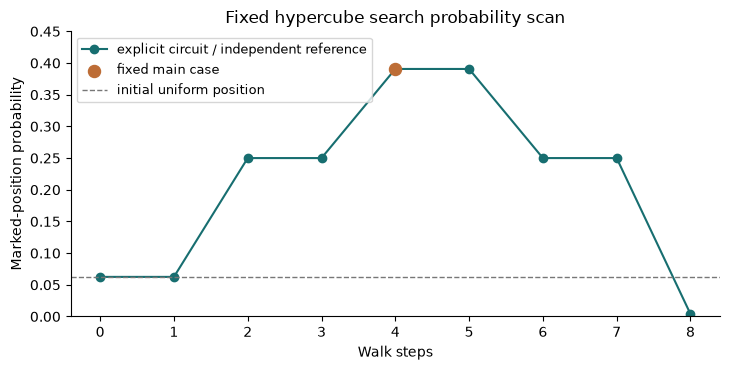

In [4]:
expected_scan = np.array([1/16, 1/16, 1/4, 1/4, 25/64, 25/64, 1/4, 1/4, 1/256])
scan = []
for steps in range(9):
    checked = opt.simulate_hypercube_walk(DIMENSION, MARKED_VERTEX, steps)
    independent = independent_skw_state(DIMENSION, MARKED_VERTEX, steps)
    p_reference = float(np.sum(np.abs(independent.reshape(layout["vertices"], DIMENSION)[MARKED_VERTEX]) ** 2))
    np.testing.assert_allclose(checked["marked_probability"], p_reference, rtol=0, atol=1e-14)
    assert checked["workspace_leakage"] < 1e-14
    scan.append(checked["marked_probability"])
np.testing.assert_allclose(scan, expected_scan, rtol=0, atol=1e-14)
print({"steps": list(range(9)), "marked_position_probabilities": scan,
       "fixed_main_steps": STEPS, "selection": "specified before this scan"})
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(range(9), scan, "o-", color="#176e70", label="explicit circuit / independent reference")
ax.scatter([STEPS], [scan[STEPS]], color="#bd6d36", s=75, zorder=3, label="fixed main case")
ax.axhline(1 / 16, color="#777777", linestyle="--", linewidth=1, label="initial uniform position")
ax.set(xlabel="Walk steps", ylabel="Marked-position probability",
       title="Fixed hypercube search probability scan", ylim=(0, 0.45))
ax.set_xticks(range(9))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


## Three ideal finite-shot readouts

Each seed uses 4,096 fresh modeled preparations of the same four-step circuit. NumPy PCG64 uses `SeedSequence([seed,5])`; namespace five separates these draws from earlier optimization examples. All 11 measured bits are retained in the count record. We report marked-position frequency, a descriptive binomial standard error, and a Hoeffding half-width

$$\epsilon_H=\sqrt{\frac{\log(2/0.05)}{2M}}$$

for **one fixed Bernoulli mean** at 95% confidence. With $M=4096$, this width is below the stated absolute frequency target 0.025. It does not make the three results a simultaneous confidence claim and does not cover physical faults, coherent circuit error, or algorithm scaling.

These counts model ideal measurement sampling. Workspace checks retain nonzero-work outcomes if any occur; they are never discarded.

{'seed': 7, 'shots': 4096, 'marked_samples': 1605, 'marked_sample_fraction': 0.391845703125, 'exact_marked_probability': 0.39062499999999767, 'estimated_standard_error': 0.00762753940916389, 'hoeffding_half_width_95': 0.02122033618344718, 'workspace_nonzero_samples': 0, 'circuit_preparations': 4096, 'oracle_calls': 16384, 'coin_calls': 16384, 'shift_calls': 16384, 'individual_qubit_measurements': 45056, 'sampling_seconds': 0.0005195680000724678}
{'seed': 19, 'shots': 4096, 'marked_samples': 1629, 'marked_sample_fraction': 0.397705078125, 'exact_marked_probability': 0.39062499999999767, 'estimated_standard_error': 0.0076472483587623, 'hoeffding_half_width_95': 0.02122033618344718, 'workspace_nonzero_samples': 0, 'circuit_preparations': 4096, 'oracle_calls': 16384, 'coin_calls': 16384, 'shift_calls': 16384, 'individual_qubit_measurements': 45056, 'sampling_seconds': 0.00046607900003436953}
{'seed': 41, 'shots': 4096, 'marked_samples': 1647, 'marked_sample_fraction': 0.402099609375, 'exac

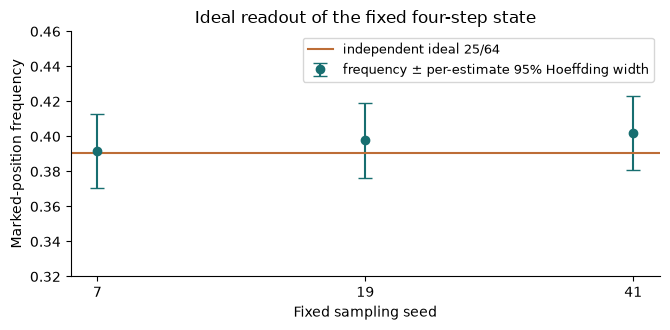

In [5]:
readouts = [opt.sample_hypercube_walk(DIMENSION, MARKED_VERTEX, STEPS, shots=SHOTS, seed=seed)
            for seed in SEEDS]
for record in readouts:
    assert sum(record["counts"].values()) == SHOTS
    assert sum(record["position_counts"].values()) == SHOTS
    assert all(len(bits) == layout["total_qubits"] for bits in record["counts"])
    assert record["workspace_nonzero_samples"] == 0
    assert record["hoeffding_half_width_95"] <= .025
    assert record["individual_qubit_measurements"] == SHOTS * 11
    print({key: record[key] for key in
           ("seed", "shots", "marked_samples", "marked_sample_fraction", "exact_marked_probability",
            "estimated_standard_error", "hoeffding_half_width_95", "workspace_nonzero_samples",
            "circuit_preparations", "oracle_calls", "coin_calls", "shift_calls",
            "individual_qubit_measurements", "sampling_seconds")})

fig, ax = plt.subplots(figsize=(6.8, 3.4))
frequencies = [record["marked_sample_fraction"] for record in readouts]
errors = [record["hoeffding_half_width_95"] for record in readouts]
ax.errorbar(range(3), frequencies, yerr=errors, fmt="o", capsize=5, color="#176e70",
            label="frequency ± per-estimate 95% Hoeffding width")
ax.axhline(25 / 64, color="#bd6d36", label="independent ideal 25/64")
ax.set_xticks(range(3), [str(seed) for seed in SEEDS])
ax.set(xlabel="Fixed sampling seed", ylabel="Marked-position frequency", ylim=(.32, .46),
       title="Ideal readout of the fixed four-step state")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


## Exact Clifford+T lowering and complete demonstrated workload

The generator exposes each clean CCX and CZ operation. Deterministic Qiskit lowering at optimization level zero uses the basis `h,x,z,s,sdg,t,tdg,cx`. Its standard exact CCX decomposition uses seven T/TDG gates. The main source has 56 CCX gates, so the lowered circuit has **392 T/TDG gates**. It contains no arbitrary rotations and needs no approximate rotation synthesis. This exact logical decomposition is distinct from the surface-code fault model and hardware scheduling in the chapter's resource analysis.

The state preparation, supplied equality oracle, coin/shift uncomputation and all final measurements are counted. The full three-seed readout has 12,288 preparations, 49,152 calls each to the oracle, coin and shift, and 135,168 individual qubit measurements. Classical circuit construction, simulator time, interpretation of bits and equality checks do not become fault-tolerant quantum runtime estimates.

For a separate fixed-state search output, independent ideal repetitions succeed at least once with probability $1-(1-p)^R$. The repetition count below uses only the validated $p=25/64$, not a general theorem about arbitrary instances. It counts a complete four-step circuit and all 11 final measurements on each trial.

In [6]:
compiled = opt.compile_walk_clifford_t(source)
compiled_counts = dict(compiled.count_ops())
assert int(source.count_ops().get("ccx", 0)) == 56
assert compiled_counts.get("t", 0) + compiled_counts.get("tdg", 0) == 392
assert set(compiled_counts) <= set(opt.WALK_CLIFFORD_T_BASIS) | {"barrier", "measure"}
assert not ({"rx", "ry", "rz"} & set(compiled_counts))
compiled_state = Statevector.from_instruction(compiled.remove_final_measurements(inplace=False))
assert state.equiv(compiled_state, atol=2e-14)

workload = {key: sum(record[key] for record in readouts) for key in
            ("circuit_preparations", "oracle_calls", "coin_calls", "shift_calls", "individual_qubit_measurements")}
assert workload == {"circuit_preparations": 12288, "oracle_calls": 49152,
                    "coin_calls": 49152, "shift_calls": 49152, "individual_qubit_measurements": 135168}
repetitions = opt.walk_repetitions(25 / 64, target_success=.99)
print({"exact_Clifford_T_gate_counts_per_preparation": compiled_counts,
       "source_depth": source.depth(), "Clifford_T_depth": compiled.depth(),
       "T_and_Tdg_per_preparation": 392,
       "three_seed_readout_workload": workload,
       "three_seed_T_and_Tdg_workload": 392 * workload["circuit_preparations"],
       "fixed_state_search_repetitions": repetitions,
       "at_least_one_marked_probability": 1 - (1 - 25/64) ** repetitions,
       "search_oracle_calls": repetitions * STEPS,
       "search_individual_qubit_measurements": repetitions * 11,
       "source_QASM_sha256": hashlib.sha256(qasm3.dumps(source).encode()).hexdigest(),
       "Clifford_T_QASM_sha256": hashlib.sha256(qasm3.dumps(compiled).encode()).hexdigest()})


{'exact_Clifford_T_gate_counts_per_preparation': {'cx': 340, 't': 224, 'tdg': 168, 'h': 158, 'x': 80, 'measure': 11, 'z': 4, 'barrier': 1}, 'source_depth': 118, 'Clifford_T_depth': 594, 'T_and_Tdg_per_preparation': 392, 'three_seed_readout_workload': {'circuit_preparations': 12288, 'oracle_calls': 49152, 'coin_calls': 49152, 'shift_calls': 49152, 'individual_qubit_measurements': 135168}, 'three_seed_T_and_Tdg_workload': 4816896, 'fixed_state_search_repetitions': 10, 'at_least_one_marked_probability': 0.9929393232300169, 'search_oracle_calls': 40, 'search_individual_qubit_measurements': 110, 'source_QASM_sha256': 'd159f757a1fd846a01c80b4e538292658e13a6593e1df20f3a7ecc4f3f981405', 'Clifford_T_QASM_sha256': '8136d61ee1cf43d8b20f613d95277d1695c53c03487bbf69098a6efb7a51da5f'}


## Generation and simulation have separate limits

The generator supports dimensions 2, 4, 8 and 16 and step counts 0 through 32, with a conservative 100,000 primitive-gate materialization cap. It charges CCX as 15 primitive operations, CZ as three, and ordinary Clifford gates as one. Width grows as $2(d+\log_2d)-1$, including $d+\log_2d-1$ clean-work qubits.

The joint marking stage costs $2(d+r-1)$ CCX per step. The shift uses $d$ CX for $r=1$, and $d(2r-3)$ CCX for $r\ge2$. The coin uses Z for $r=1$, CZ for $r=2$, and $2(r-1)$ CCX for larger $r$. H and X wrappers also contribute to the source counts. This explicit construction has $O(d\log d)$ gates per step and $O(d)$ qubits; those generation counts do not demonstrate an application speedup.

The ideal statevector hard cap is **12 total qubits**, covering only dimensions two and four with this clean-work construction. The independent dense reference is capped at **six active qubits**. The larger dimensions below are generated and counted but not simulated or numerically validated here. Source materialization is distinct from a scalable simulator or a proven success probability.

In [7]:
scaling_rows = []
for dimension in (2, 4, 8, 16):
    generated = opt.build_hypercube_walk_circuit(dimension, marked_vertex=1, steps=4, measure=True)
    registers = opt.walk_register_layout(dimension)
    scaling_rows.append({"dimension": dimension, "vertices": registers["vertices"],
                         "total_qubits": generated.num_qubits,
                         "source_gate_counts": dict(generated.count_ops()),
                         "primitive_cap_cost": generated.metadata["primitive_cap_cost"],
                         "simulation_coverage": "bounded simulator supported" if dimension <= 4 else
                                                "source generation only; not simulated"})
print(scaling_rows)
for dimension in (8, 16):
    try:
        opt.simulate_hypercube_walk(dimension, marked_vertex=1, steps=4)
    except ValueError as exc:
        print({"dimension": dimension, "expected_simulation_limit": str(exc)})
    else:
        raise AssertionError("The bounded simulator must reject the larger generated examples.")


[{'dimension': 2, 'vertices': 4, 'total_qubits': 5, 'source_gate_counts': {'x': 32, 'h': 19, 'ccx': 16, 'z': 8, 'cx': 8, 'measure': 5, 'barrier': 1}, 'primitive_cap_cost': 307, 'simulation_coverage': 'bounded simulator supported'}, {'dimension': 4, 'vertices': 16, 'total_qubits': 11, 'source_gate_counts': {'x': 88, 'ccx': 56, 'h': 38, 'measure': 11, 'z': 4, 'cz': 4, 'barrier': 1}, 'primitive_cap_cost': 982, 'simulation_coverage': 'bounded simulator supported'}, {'dimension': 8, 'vertices': 256, 'total_qubits': 21, 'source_gate_counts': {'x': 200, 'ccx': 192, 'h': 59, 'measure': 21, 'z': 8, 'barrier': 1}, 'primitive_cap_cost': 3147, 'simulation_coverage': 'source generation only; not simulated'}, {'dimension': 16, 'vertices': 65536, 'total_qubits': 39, 'source_gate_counts': {'ccx': 496, 'x': 440, 'h': 84, 'measure': 39, 'z': 8, 'barrier': 1}, 'primitive_cap_cost': 7972, 'simulation_coverage': 'source generation only; not simulated'}]
{'dimension': 8, 'expected_simulation_limit': 'walk s

The chapter publishes the matching generator, implementation, exact source and Clifford+T QASM, structured run records, and fault-tolerant resource analysis. The results above validate the fixed ideal circuit, its readout convention and its independent tiny reference. Large-instance performance, hardware accuracy and a formal full-algorithm proof remain outside this check.